<a href="https://colab.research.google.com/github/Mehedi-Hasan-Robel/ML-project/blob/ml-project/Heart_Failure_Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/content/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [4]:
df.shape

(918, 12)

In [5]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [6]:
df.dtypes

,0
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [8]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [11]:
df.describe(include = 'object')

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


In [12]:
df['Sex'].unique()

array(['M', 'F'], dtype=object)

In [13]:
df['Sex'].value_counts()

,count
Sex,
M,725
F,193


In [14]:
df['Sex'].value_counts(normalize = True)*100

,proportion
Sex,
M,78.976035
F,21.023965


In [15]:
df['ChestPainType'].unique()

array(['ATA', 'NAP', 'ASY', 'TA'], dtype=object)

In [16]:
df['ChestPainType'].value_counts()

,count
ChestPainType,
ASY,496
NAP,203
ATA,173
TA,46


In [17]:
df['ChestPainType'].value_counts(normalize = True)*100

,proportion
ChestPainType,
ASY,54.030501
NAP,22.113290
ATA,18.845316
TA,5.010893


In [18]:
df['RestingECG'].unique()

array(['Normal', 'ST', 'LVH'], dtype=object)

In [19]:
df['RestingECG'].value_counts()

,count
RestingECG,
Normal,552
LVH,188
ST,178


In [20]:
df['RestingECG'].value_counts(normalize = True)*100

,proportion
RestingECG,
Normal,60.130719
LVH,20.479303
ST,19.389978


In [21]:
df['ExerciseAngina'].unique()

array(['N', 'Y'], dtype=object)

In [22]:
df['ExerciseAngina'].value_counts()

,count
ExerciseAngina,
N,547
Y,371


In [23]:
df['ExerciseAngina'].value_counts(normalize=True)*100

,proportion
ExerciseAngina,
N,59.586057
Y,40.413943


In [24]:
df['ST_Slope'].unique()

array(['Up', 'Flat', 'Down'], dtype=object)

In [25]:
df['ST_Slope'].value_counts()

,count
ST_Slope,
Flat,460
Up,395
Down,63


In [26]:
df['ST_Slope'].value_counts(normalize=True)*100

,proportion
ST_Slope,
Flat,50.108932
Up,43.028322
Down,6.862745


In [27]:

df_grouped = df.groupby('HeartDisease')[['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']].mean().reset_index()
print(df_grouped)

   HeartDisease        Age   RestingBP  Cholesterol       MaxHR   Oldpeak
0             0  50.551220  130.180488   227.121951  148.151220  0.408049
1             1  55.899606  134.185039   175.940945  127.655512  1.274213


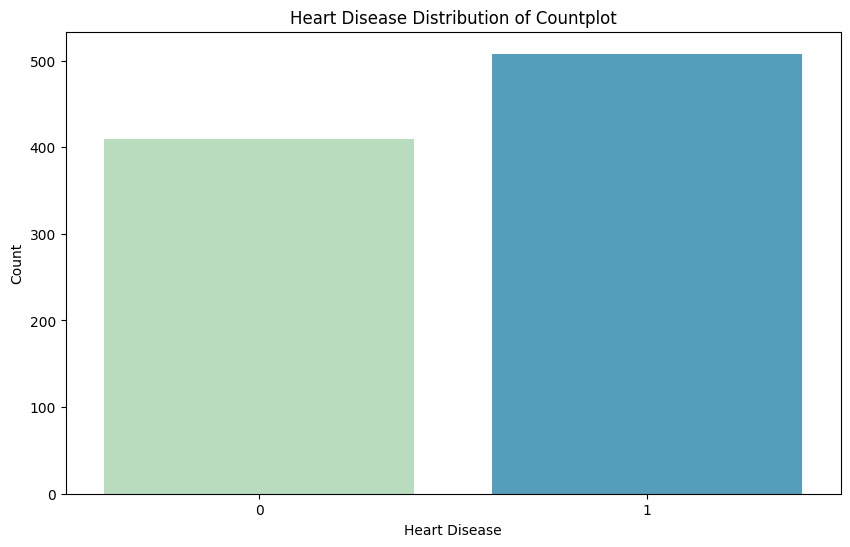

In [28]:
plt.figure(figsize=(10, 6))
sns.countplot(x='HeartDisease', data=df,palette='GnBu')
plt.xlabel('Heart Disease')
plt.ylabel('Count')
plt.title('Heart Disease Distribution of Countplot')
plt.show()

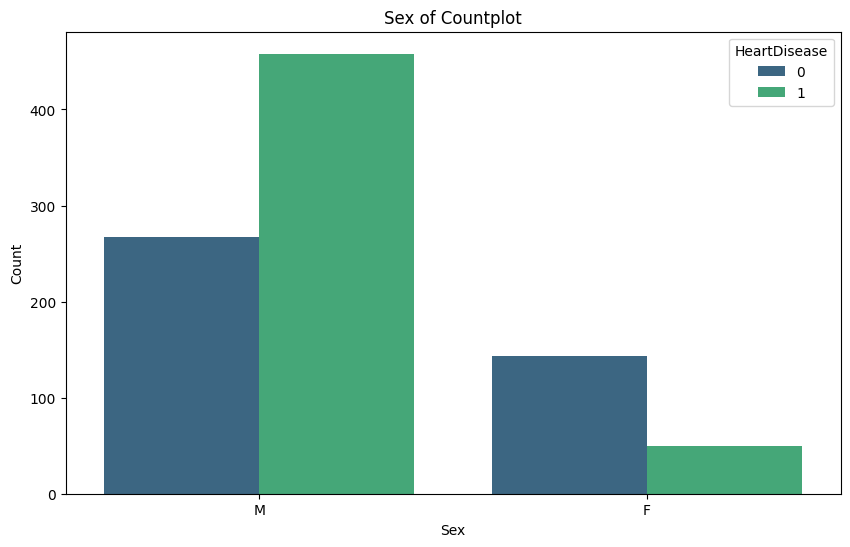

In [29]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Sex', data=df, hue = 'HeartDisease',palette='viridis')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Sex of Countplot')
plt.show()

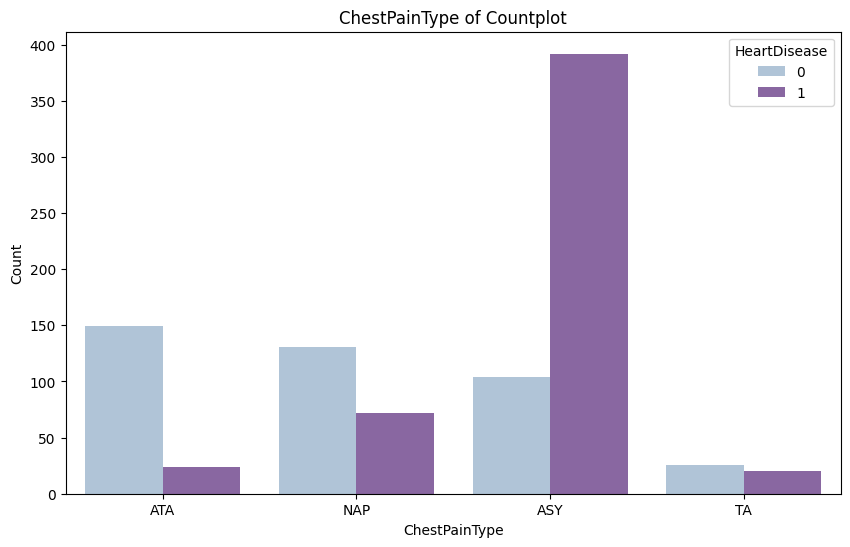

In [30]:
plt.figure(figsize=(10, 6))
sns.countplot(x='ChestPainType', data=df, hue = 'HeartDisease', palette='BuPu')
plt.xlabel('ChestPainType')
plt.ylabel('Count')
plt.title('ChestPainType of Countplot')
plt.show()

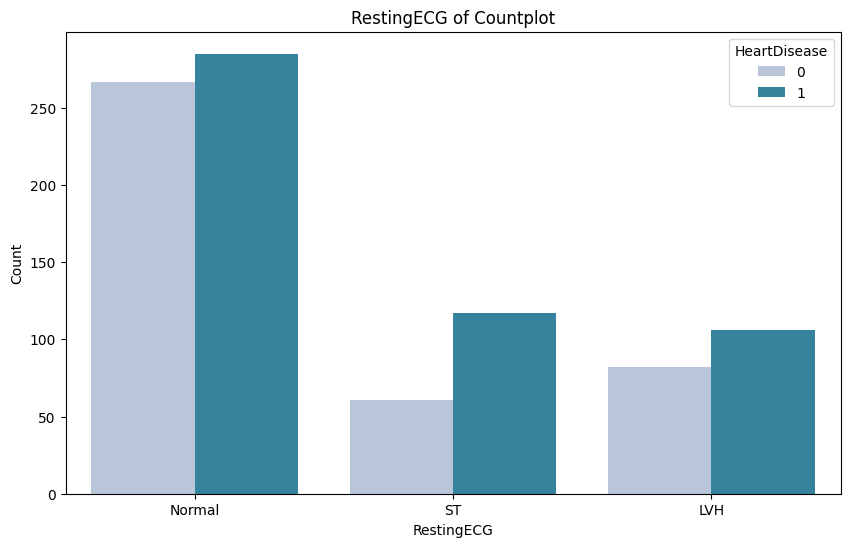

In [31]:
plt.figure(figsize=(10, 6))
sns.countplot(x='RestingECG', data=df, hue = 'HeartDisease', palette='PuBuGn')
plt.xlabel('RestingECG')
plt.ylabel('Count')
plt.title('RestingECG of Countplot')
plt.show()

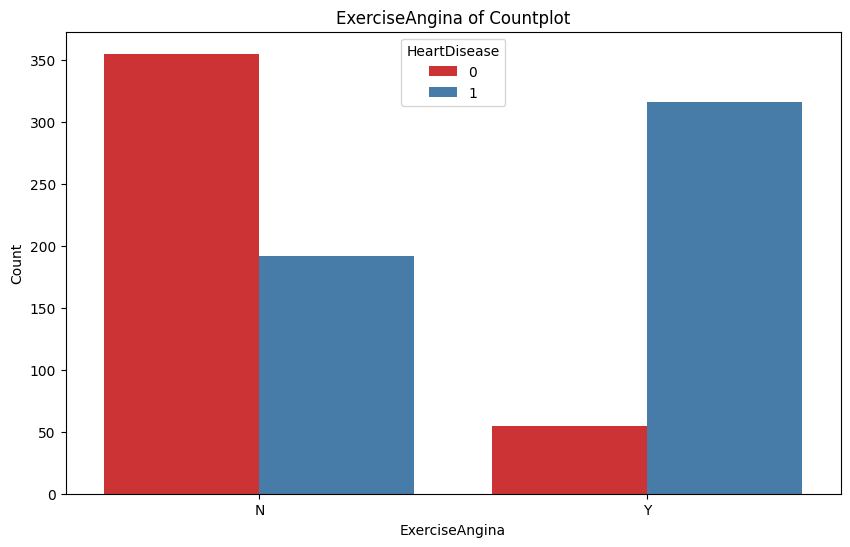

In [32]:
plt.figure(figsize=(10, 6))
sns.countplot(x='ExerciseAngina', data=df, hue = 'HeartDisease', palette='Set1')
plt.xlabel('ExerciseAngina')
plt.ylabel('Count')
plt.title('ExerciseAngina of Countplot')
plt.show()

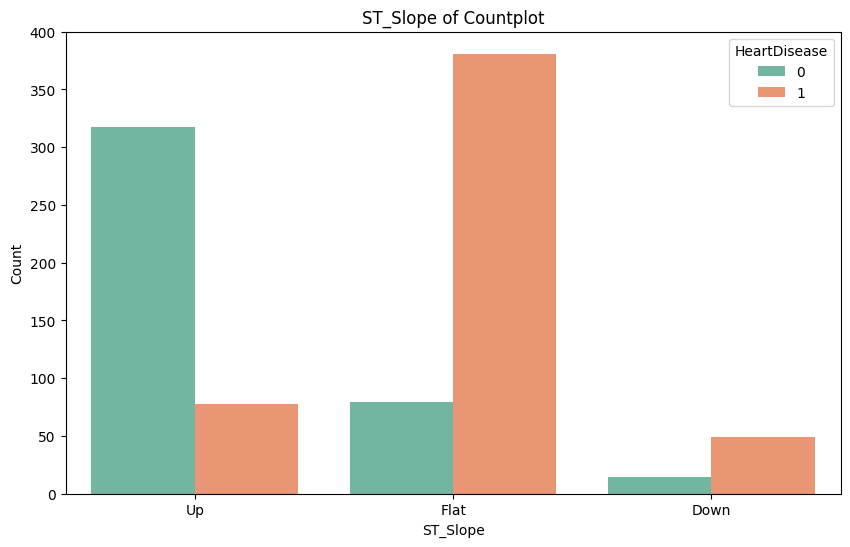

In [33]:
plt.figure(figsize=(10, 6))
sns.countplot(x='ST_Slope', data=df, hue = 'HeartDisease', palette='Set2')
plt.xlabel('ST_Slope')
plt.ylabel('Count')
plt.title('ST_Slope of Countplot')
plt.show()

<Figure size 1200x800 with 0 Axes>

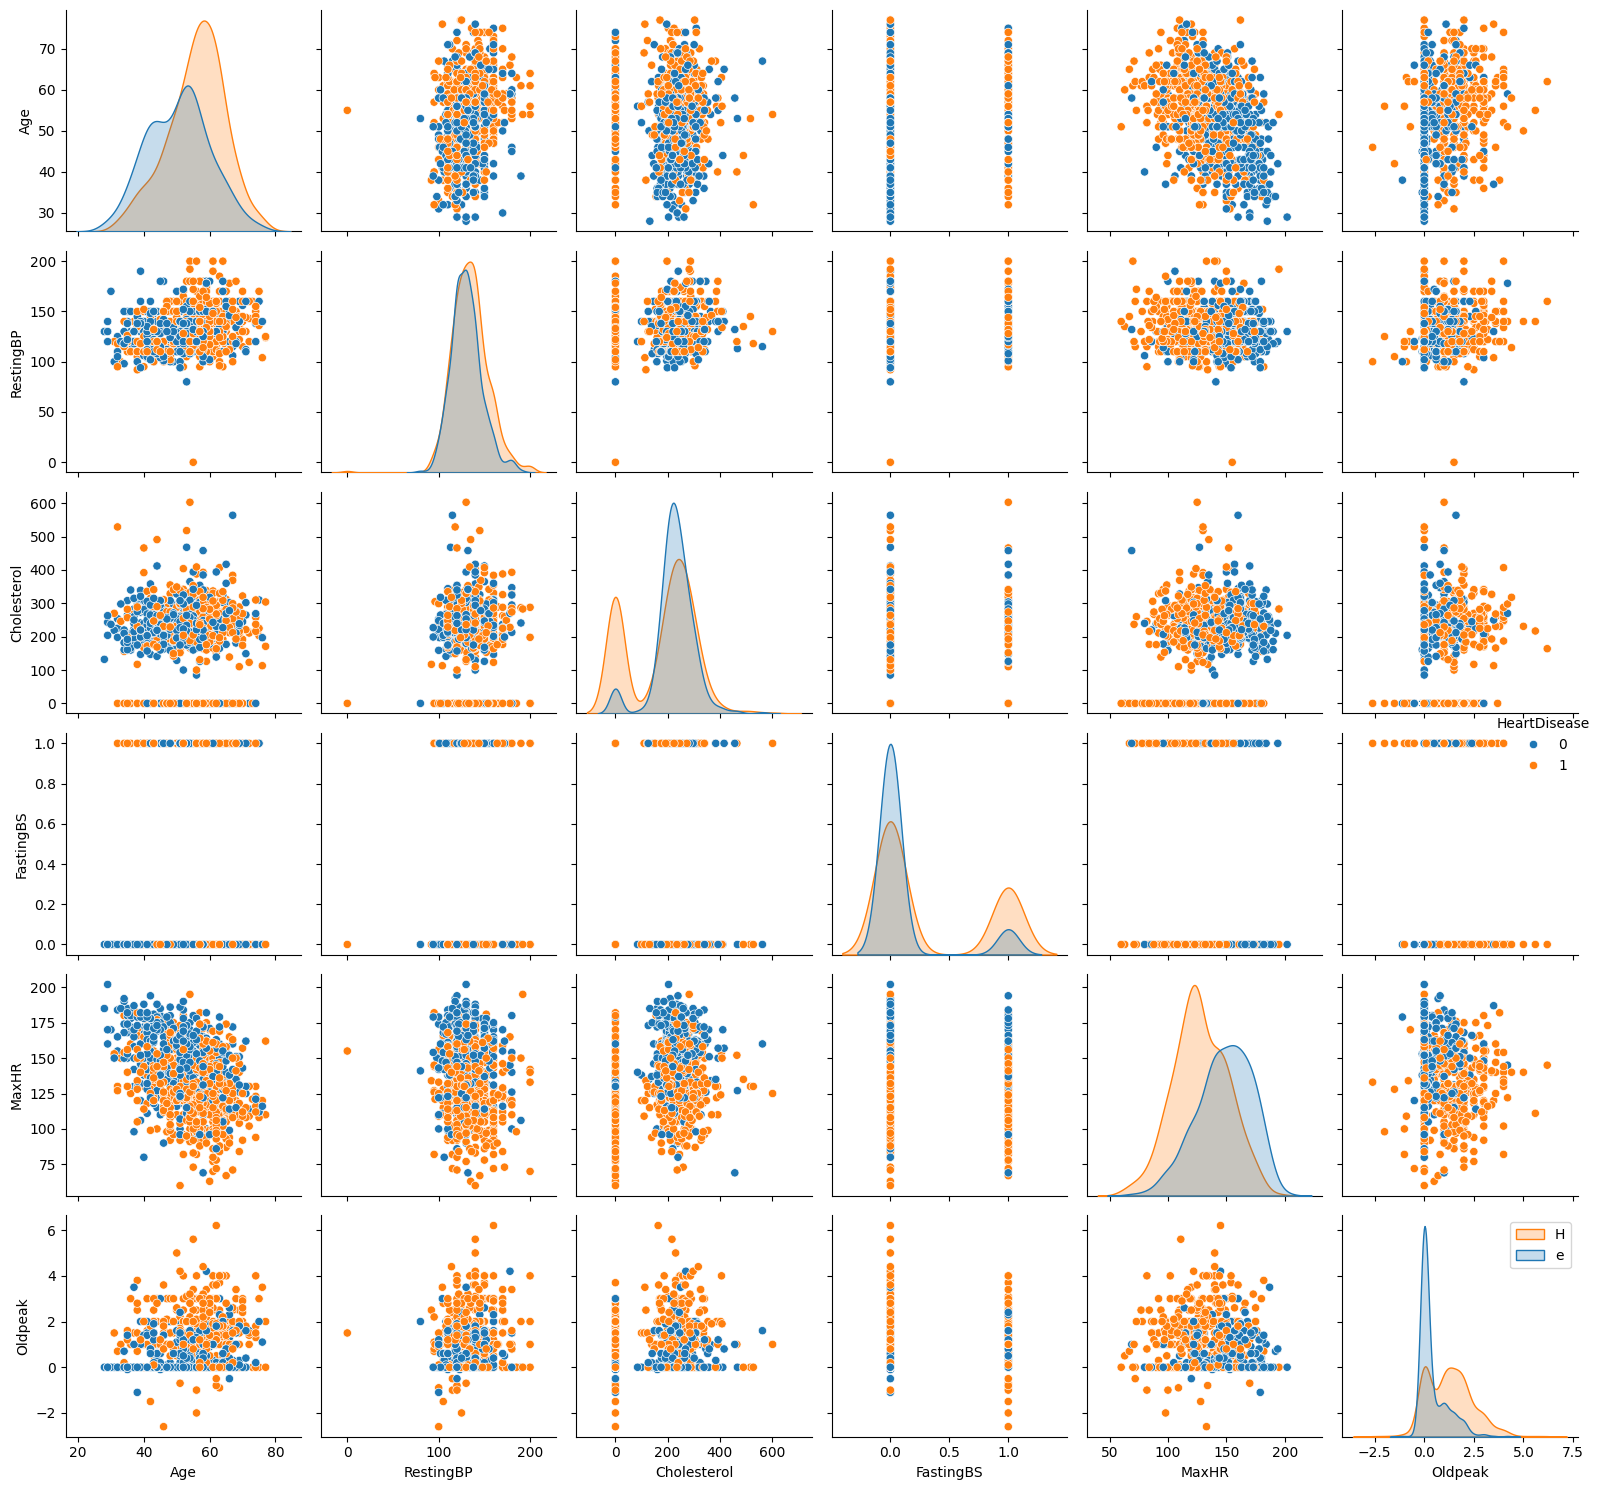

In [34]:
plt.figure(figsize=(12,8))
sns.pairplot(df,hue="HeartDisease")
plt.legend("HeartDisease")
plt.tight_layout()
plt.show()

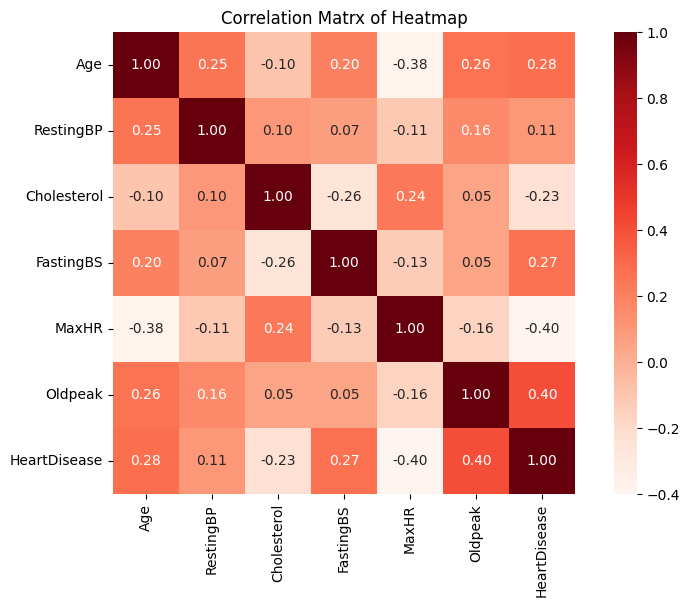

In [35]:
corr_matrix = df.corr(numeric_only = True)
plt.figure(figsize = (10,6))
sns.heatmap(corr_matrix,annot = True,fmt = '.2f',cmap = 'Reds',square = True)
plt.title('Correlation Matrx of Heatmap')
plt.show()

In [36]:
cat_cols = df.select_dtypes(include = 'object').columns.tolist()
cat_cols

['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

In [37]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])
df['ChestPainType'] = le.fit_transform(df['ChestPainType'])
df['RestingECG'] = le.fit_transform(df['RestingECG'])
df['ExerciseAngina'] = le.fit_transform(df['ExerciseAngina'])
df['ST_Slope'] = le.fit_transform(df['ST_Slope'])

In [38]:
df['Sex'].unique()

array([1, 0])

In [39]:
df['ChestPainType'].unique()

array([1, 2, 0, 3])

In [40]:
df['RestingECG'].unique()

array([1, 2, 0])

In [41]:
df['ExerciseAngina'].unique()

array([0, 1])

In [42]:
df['ST_Slope'].unique()

array([2, 1, 0])

In [43]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [44]:
x = df.drop('HeartDisease',axis = 1)
y = df['HeartDisease']

In [45]:
x.shape

(918, 11)

In [46]:
y.shape

(918,)

In [47]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,shuffle = True,random_state = 42)

In [48]:
x_train.shape

(734, 11)

In [49]:
y_train.shape

(734,)

In [50]:
x_test.shape

(184, 11)

In [51]:
y_test.shape

(184,)

In [52]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

In [53]:
x_train_scaler

array([[0.27083333, 1.        , 0.66666667, ..., 0.        , 0.38636364,
        0.        ],
       [0.14583333, 1.        , 0.66666667, ..., 0.        , 0.29545455,
        1.        ],
       [0.5625    , 1.        , 0.        , ..., 1.        , 0.40909091,
        0.5       ],
       ...,
       [0.64583333, 1.        , 0.        , ..., 1.        , 0.45454545,
        1.        ],
       [0.64583333, 1.        , 0.        , ..., 1.        , 0.29545455,
        1.        ],
       [0.22916667, 0.        , 0.        , ..., 0.        , 0.52272727,
        0.5       ]])

In [54]:
x_test_scaler

array([[0.70833333, 0.        , 0.33333333, ..., 0.        , 0.29545455,
        1.        ],
       [0.5       , 1.        , 0.66666667, ..., 0.        , 0.29545455,
        0.5       ],
       [0.75      , 1.        , 0.        , ..., 0.        , 0.43181818,
        0.5       ],
       ...,
       [0.72916667, 1.        , 0.        , ..., 1.        , 0.46590909,
        0.5       ],
       [0.41666667, 1.        , 0.33333333, ..., 0.        , 0.36363636,
        1.        ],
       [0.72916667, 1.        , 0.        , ..., 1.        , 0.40909091,
        0.5       ]])

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report




In [56]:
log_reg = LogisticRegression()
log_reg.fit(x_train_scaler,y_train)
y_pred_log_reg = log_reg.predict(x_test_scaler)

In [57]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
k_fold = KFold(n_splits = 5,shuffle = True,random_state = 42)
k_fold


KFold(n_splits=5, random_state=42, shuffle=True)

In [58]:
cvs = cross_val_score(log_reg,x_train_scaler,y_train, cv = k_fold, scoring = 'accuracy')
print(cvs)
print(cvs.mean())
print(cvs.std())

[0.9047619  0.81632653 0.85034014 0.87755102 0.81506849]
0.8528096169974839
0.03485020402875008


In [59]:
log_reg_accuracy = accuracy_score(y_test,y_pred_log_reg)
log_reg_precision = precision_score(y_test,y_pred_log_reg)
log_reg_recall = recall_score(y_test,y_pred_log_reg)
log_reg_f1 = f1_score(y_test,y_pred_log_reg)

In [60]:
print('Accuracy:',log_reg_accuracy)
print('Precision:',log_reg_precision)
print('Recall:',log_reg_recall)
print('F1 Score:',log_reg_f1)

Accuracy: 0.8478260869565217
Precision: 0.9072164948453608
Recall: 0.822429906542056
F1 Score: 0.8627450980392157


In [61]:
log_cm = confusion_matrix(y_test,y_pred_log_reg)
log_cm

array([[68,  9],
       [19, 88]])

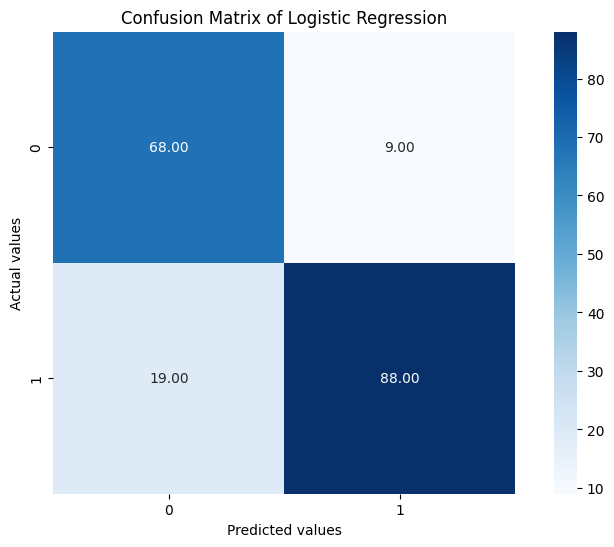

In [62]:
plt.figure(figsize = (10,6))
sns.heatmap(log_cm, annot = True, fmt = '.2f', cmap = 'Blues', square = True)
plt.xlabel('Predicted values')
plt.ylabel('Actual values')
plt.title('Confusion Matrix of Logistic Regression')
plt.show()

In [63]:
print(classification_report(y_test,y_pred_log_reg))

              precision    recall  f1-score   support

           0       0.78      0.88      0.83        77
           1       0.91      0.82      0.86       107

    accuracy                           0.85       184
   macro avg       0.84      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



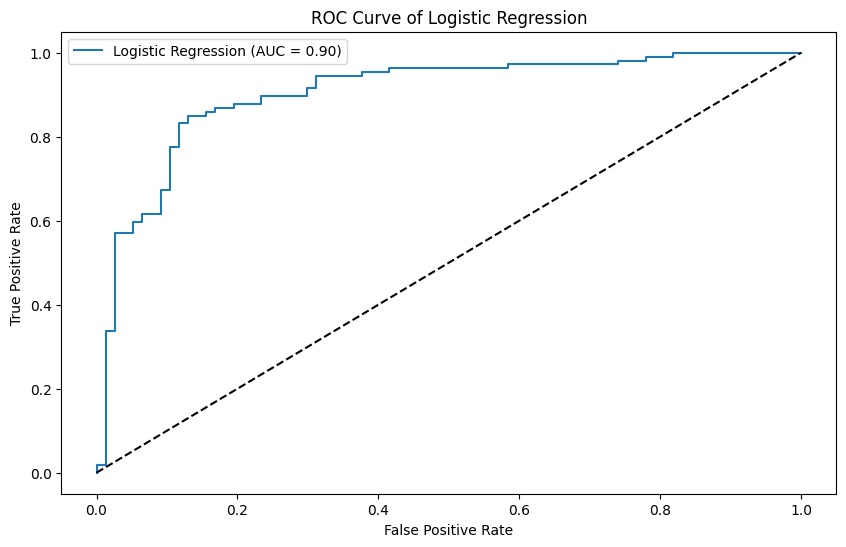

In [64]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score


y_proba_log = log_reg.predict_proba(x_test_scaler)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba_log)
auc = roc_auc_score(y_test, y_proba_log)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label='Logistic Regression (AUC = %0.2f)' % auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Logistic Regression')
plt.legend()
plt.show()

In [65]:

dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(x_train_scaler, y_train)

y_pred_dt = dt_classifier.predict(x_test_scaler)

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
k_fold_dt = KFold(n_splits = 5,shuffle = True,random_state = 42)
k_fold_dt





KFold(n_splits=5, random_state=42, shuffle=True)

In [66]:
cvs_dt = cross_val_score(dt_classifier,x_train_scaler,y_train, cv = k_fold_dt, scoring = 'accuracy')
print(cvs_dt)
print(cvs_dt.mean())
print(cvs_dt.std())

[0.84353741 0.76190476 0.78231293 0.71428571 0.80821918]
0.7820519988817445
0.043505002532227194


In [67]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)


print('Decision Tree Metrics:')
print('Accuracy: ', dt_accuracy)
print('Precision:', dt_precision)
print('Recall:   ', dt_recall)
print('F1 Score: ', dt_f1)

Decision Tree Metrics:
Accuracy:  0.7880434782608695
Precision: 0.8617021276595744
Recall:    0.7570093457943925
F1 Score:  0.8059701492537313


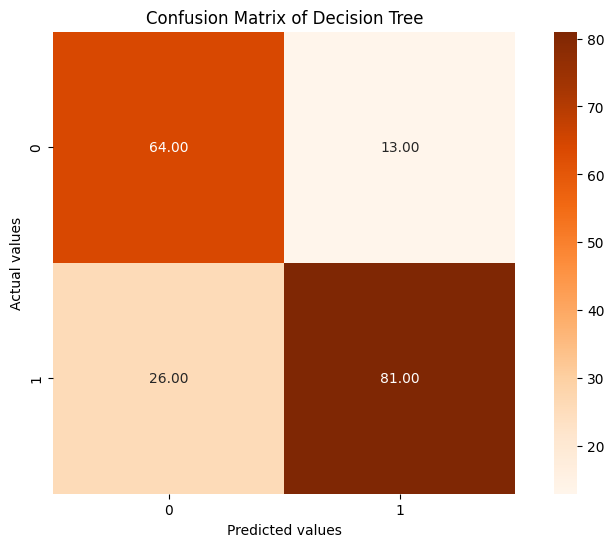

In [68]:

dt_cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(10, 6))
sns.heatmap(dt_cm, annot=True, fmt='.2f', cmap='Oranges', square=True)
plt.xlabel('Predicted values')
plt.ylabel('Actual values')
plt.title('Confusion Matrix of Decision Tree')
plt.show()

In [69]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.71      0.83      0.77        77
           1       0.86      0.76      0.81       107

    accuracy                           0.79       184
   macro avg       0.79      0.79      0.79       184
weighted avg       0.80      0.79      0.79       184



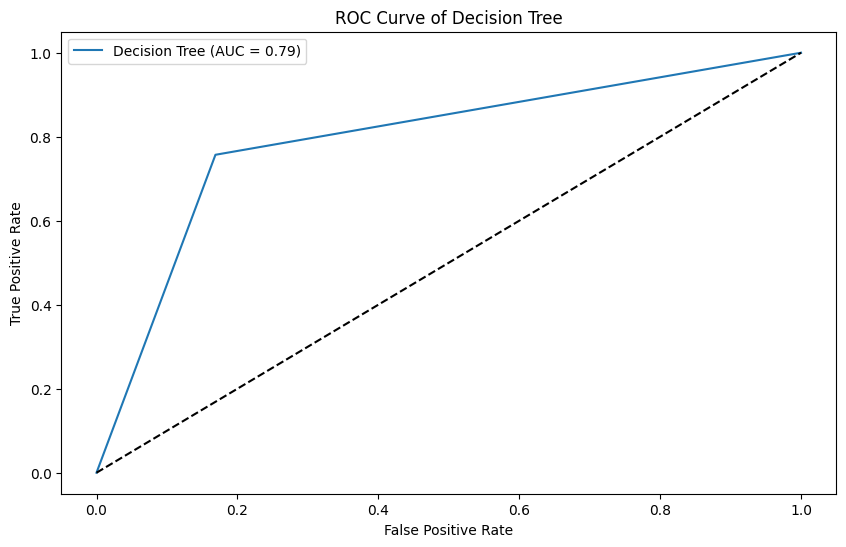

In [70]:
y_proba_dt = dt_classifier.predict_proba(x_test_scaler)[:,1]
fpr,tpr,thresholds = roc_curve(y_test,y_proba_dt)
auc = roc_auc_score(y_test,y_proba_dt)

plt.figure(figsize=(10,6))
plt.plot(fpr,tpr,label = 'Decision Tree (AUC = %0.2f)' % auc)
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Decision Tree')
plt.legend()
plt.show()


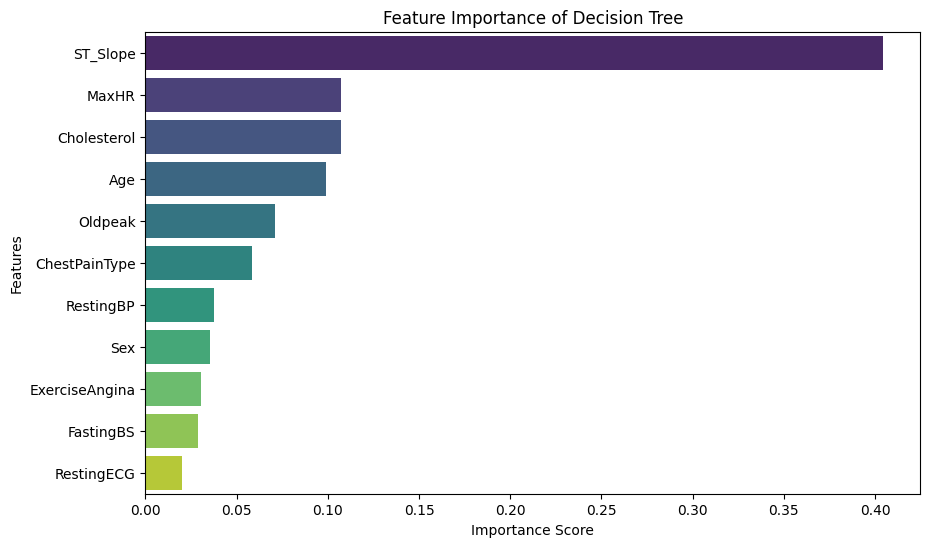

In [71]:

importances = dt_classifier.feature_importances_
feature_names = x.columns


feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance of Decision Tree')
plt.show()

In [72]:
from sklearn.ensemble import RandomForestClassifier


rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(x_train_scaler, y_train)

y_pred_rf = rf_classifier.predict(x_test_scaler)
y_proba_rf = rf_classifier.predict_proba(x_test_scaler)[:, 1]


k_fold_rf = KFold(n_splits = 5,shuffle = True,random_state = 42)
k_fold_rf

cvs_rf = cross_val_score(rf_classifier, x_train_scaler, y_train, cv=k_fold_rf, scoring='accuracy')
print('Random Forest Cross-Validation')
print(cvs_rf)
print(cvs_rf.mean())
print(cvs_rf.std())





Random Forest Cross-Validation
[0.92517007 0.80952381 0.85714286 0.85714286 0.82191781]
0.8541794800111825
0.04022976800430843


In [73]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
print('Random Forest Test Metrics ')
print(f'Accuracy:  {rf_accuracy:.2f}')
print(f'Precision: {rf_precision:.2f}')
print(f'Recall:    {rf_recall:.2f}')
print(f'F1 Score:  {rf_f1:.2f}')

Random Forest Test Metrics 
Accuracy:  0.88
Precision: 0.90
Recall:    0.90
F1 Score:  0.90


In [74]:

print(' Classification Report ')
print(classification_report(y_test, y_pred_rf))

 Classification Report 
              precision    recall  f1-score   support

           0       0.86      0.86      0.86        77
           1       0.90      0.90      0.90       107

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



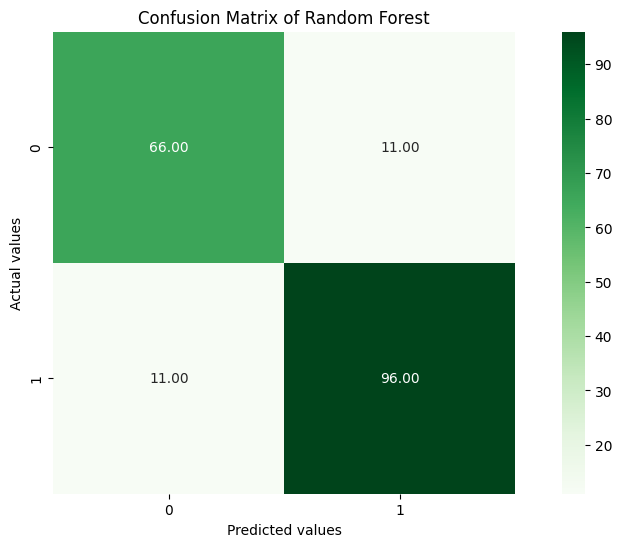

In [75]:
rf_cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(12, 6))
sns.heatmap(rf_cm, annot=True, fmt='.2f', cmap='Greens', square=True)
plt.xlabel('Predicted values')
plt.ylabel('Actual values')
plt.title('Confusion Matrix of Random Forest')
plt.show()

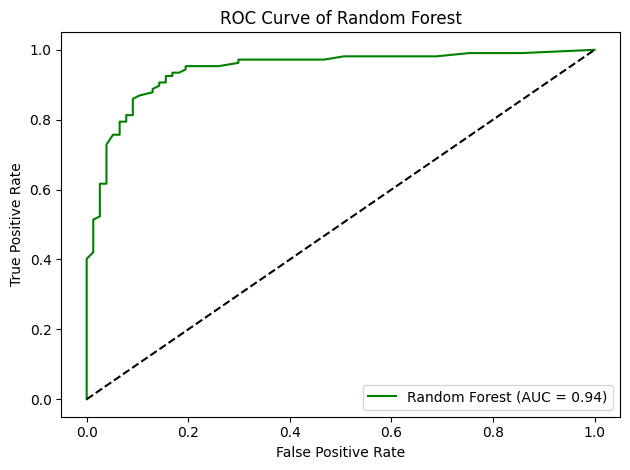

In [76]:


y_proba_rf = rf_classifier.predict_proba(x_test_scaler)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)

plt.plot(fpr_rf, tpr_rf, color='green', label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of Random Forest')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

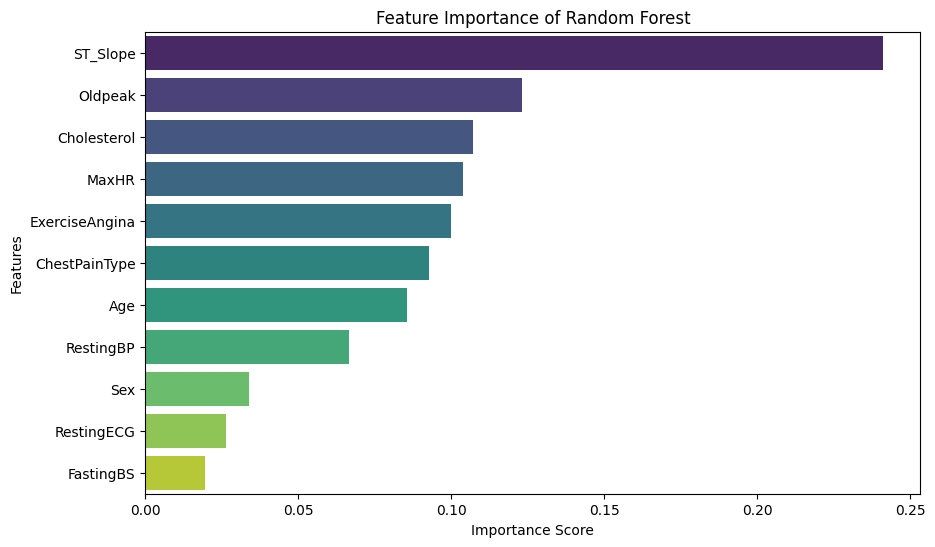

In [77]:

rf_importances = rf_classifier.feature_importances_

rf_feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=rf_feature_importance_df, palette='viridis')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance of Random Forest')
plt.show()

In [78]:
from xgboost import XGBClassifier


xgb_classifier = XGBClassifier(random_state=42)
xgb_classifier.fit(x_train_scaler, y_train)


y_pred_xgb = xgb_classifier.predict(x_test_scaler)
y_proba_xgb = xgb_classifier.predict_proba(x_test_scaler)[:, 1]


k_fold_xgb = KFold(n_splits = 5,shuffle = True,random_state = 42)
k_fold_xgb

cvs_xgb = cross_val_score(xgb_classifier, x_train_scaler, y_train, cv= k_fold_xgb, scoring='accuracy')

print(' XGBoost Cross-Validation')
print(cvs_xgb)
print(cvs_xgb.mean())
print(cvs_xgb.std())





 XGBoost Cross-Validation
[0.92517007 0.81632653 0.83673469 0.84353741 0.82876712]
0.8501071661541328
0.03860816662372283


In [79]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
print('XGBoost Test Metrics')
print(f'Accuracy:  {xgb_accuracy:.4f}')
print(f'Precision: {xgb_precision:.4f}')
print(f'Recall:    {xgb_recall:.4f}')
print(f'F1 Score:  {xgb_f1:.4f}')

XGBoost Test Metrics
Accuracy:  0.8696
Precision: 0.9192
Recall:    0.8505
F1 Score:  0.8835


In [80]:
print('Classification Report')
print(classification_report(y_test, y_pred_xgb))

Classification Report
              precision    recall  f1-score   support

           0       0.81      0.90      0.85        77
           1       0.92      0.85      0.88       107

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184



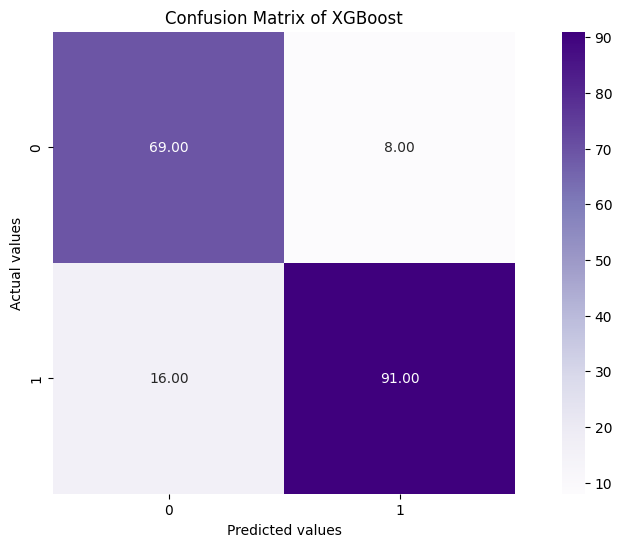

In [81]:

xgb_cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(12, 6))

sns.heatmap(xgb_cm, annot=True, fmt='.2f', cmap='Purples', square=True)
plt.xlabel('Predicted values')
plt.ylabel('Actual values')
plt.title('Confusion Matrix of XGBoost')
plt.show()




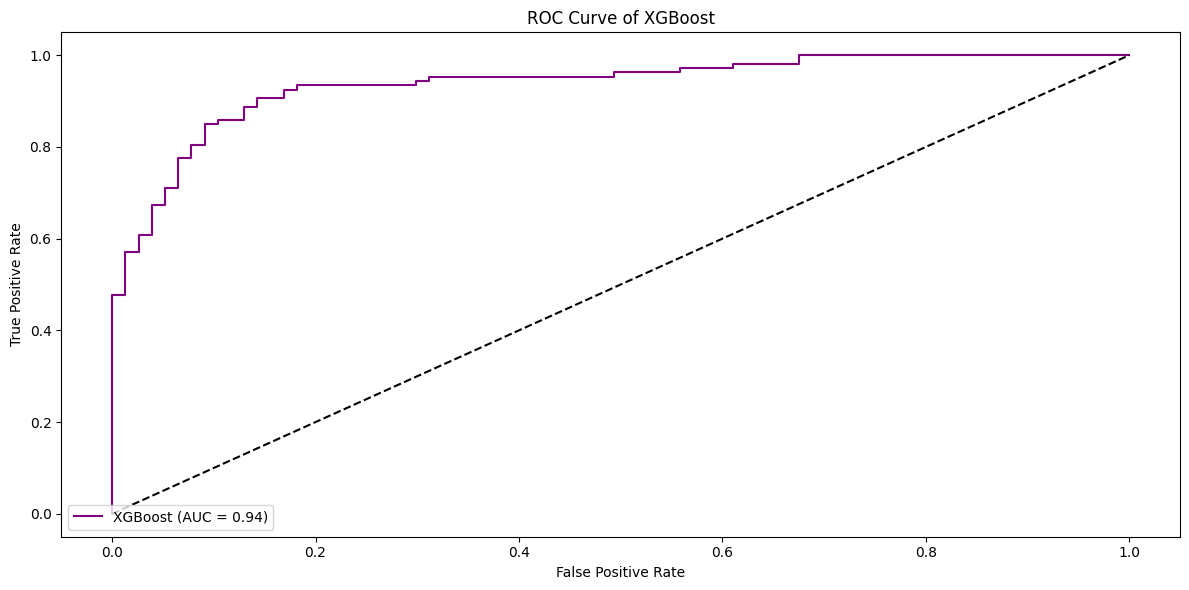

In [82]:

y_proba_xgb = xgb_classifier.predict_proba(x_test_scaler)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

plt.figure(figsize=(12, 6))

plt.plot(fpr_xgb, tpr_xgb, color='purple', label=f'XGBoost (AUC = {auc_xgb:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve of XGBoost')
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

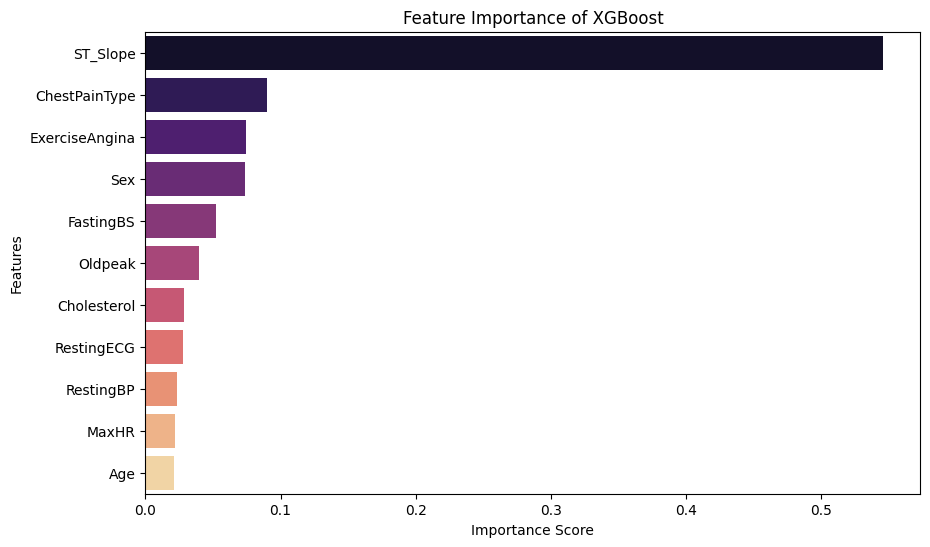

In [83]:

xgb_importances = xgb_classifier.feature_importances_

xgb_feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=xgb_feature_importance_df, palette='magma')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance of XGBoost')
plt.show()

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


performance_data = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [log_reg_accuracy, dt_accuracy, rf_accuracy, xgb_accuracy],
    'Precision': [log_reg_precision, dt_precision, rf_precision, xgb_precision],
    'Recall': [log_reg_recall, dt_recall, rf_recall, xgb_recall],
    'F1-Score': [log_reg_f1, dt_f1, rf_f1, xgb_f1],
    'AUC-ROC': [auc, auc, auc_rf, auc_xgb]
}

performance_df = pd.DataFrame(performance_data)
print(performance_df)

                 Model  Accuracy  Precision    Recall  F1-Score   AUC-ROC
0  Logistic Regression  0.847826   0.907216  0.822430  0.862745  0.794089
1        Decision Tree  0.788043   0.861702  0.757009  0.805970  0.794089
2        Random Forest  0.880435   0.897196  0.897196  0.897196  0.943015
3              XGBoost  0.869565   0.919192  0.850467  0.883495  0.936643


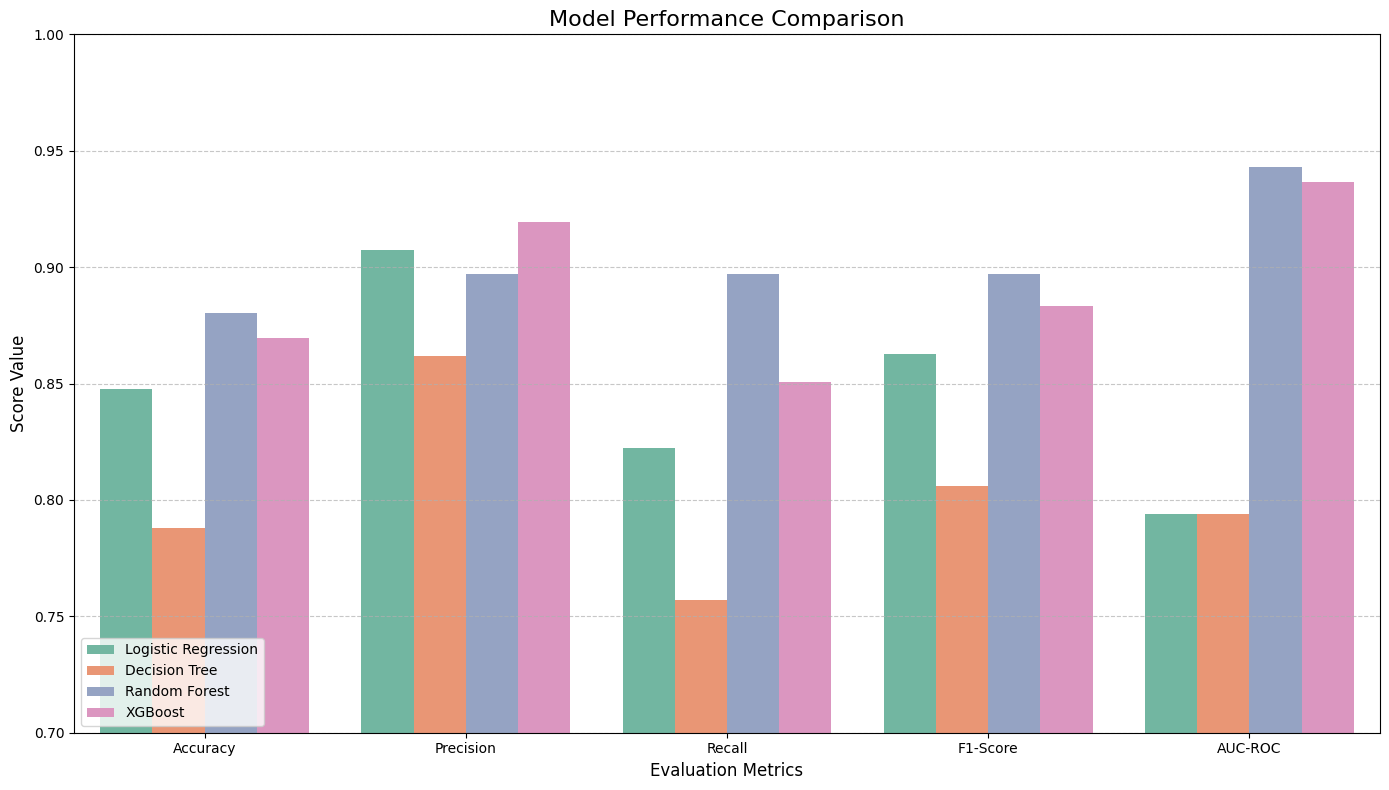

In [85]:

df_melted = performance_df.melt(id_vars='Model', var_name='Metric', value_name='Value')


plt.figure(figsize=(14, 8))
sns.barplot(x='Metric', y='Value', hue='Model', data=df_melted, palette='Set2')
plt.title('Model Performance Comparison', fontsize=16)
plt.ylabel('Score Value', fontsize=12)
plt.xlabel('Evaluation Metrics', fontsize=12)
plt.ylim(0.7, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()